# 多分类

本实验将探索一个使用神经网络进行多分类的例子

神经网络经常用于对数据进行分类，例如，神经网络可以：
* 接收照片，并且识别照片主题(狗，猫，马，其他)
* 接收一个句子，并将其中各成分的词性分为名词，动词，形容词等

这类网络的最后一层包含多个单元，每个输出对应一个类别，数值最大的输出所对应的类别就是网络的预测结果。如果将输出传入 softmax 函数，softmax 的输出就会给出输入属于各个类别的概率

先导入相关包

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
np.set_printoptions(precision=2)
from lab_utils_multiclass_TF import *
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

## 数据集

首先创建一个四分类数据集，使用`scikit-learn`中的`make_blobs`函数创建一个二维数据集，其中包含四个类别的数据点，总共100个数据点，每个数据点有2个特征

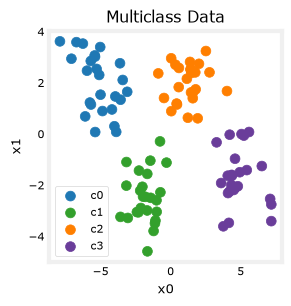

In [2]:
# 创建用于分类的四类别数据集
classes = 4
m = 100
centers = [[-5, 2], [-2, -2], [1, 2], [5, -2]] # 指定四个类别在二维坐标系的中心点
std = 1.0 # 标准差，控制数据点的分布范围
X_train, y_train = make_blobs(n_samples=m, centers=centers, cluster_std=std, n_features=2, random_state=30)

# 数据可视化
plt_mc(X_train,y_train,classes, centers, std=std)

这个数据集人工生成，没有什么实际意义，只是为了演示神经网络的多分类功能

每个点代表一个训练样本，坐标轴表示样本的两个特征，颜色表示类别，训练完成后，我们向模型提供一个新样本，模型会根据样本特征预测出该样本属于哪个类别

In [3]:
# 显示数据集中的类别
print(f"unique classes {np.unique(y_train)}")
# 显示类别的表示方式
print(f"class representation {y_train[:10]}")
# 显示数据集的形状
print(f"shape of X_train: {X_train.shape}, shape of y_train: {y_train.shape}")

unique classes [0 1 2 3]
class representation [3 3 3 0 3 3 3 3 2 0]
shape of X_train: (100, 2), shape of y_train: (100,)


## 模型构建

本实验使用一个两层网络，隐藏层包含两个神经元，输出层输出四个类别的概率

注意，输出层使用`linear`激活函数，而不是`softmax`，线性输出传入损失函数具有更好的数值稳定性，模型先输出原始分数（logits），把 softmax 和交叉熵的计算一起交给损失
函数处理，通常更稳定

线性激活函数就是原样输出

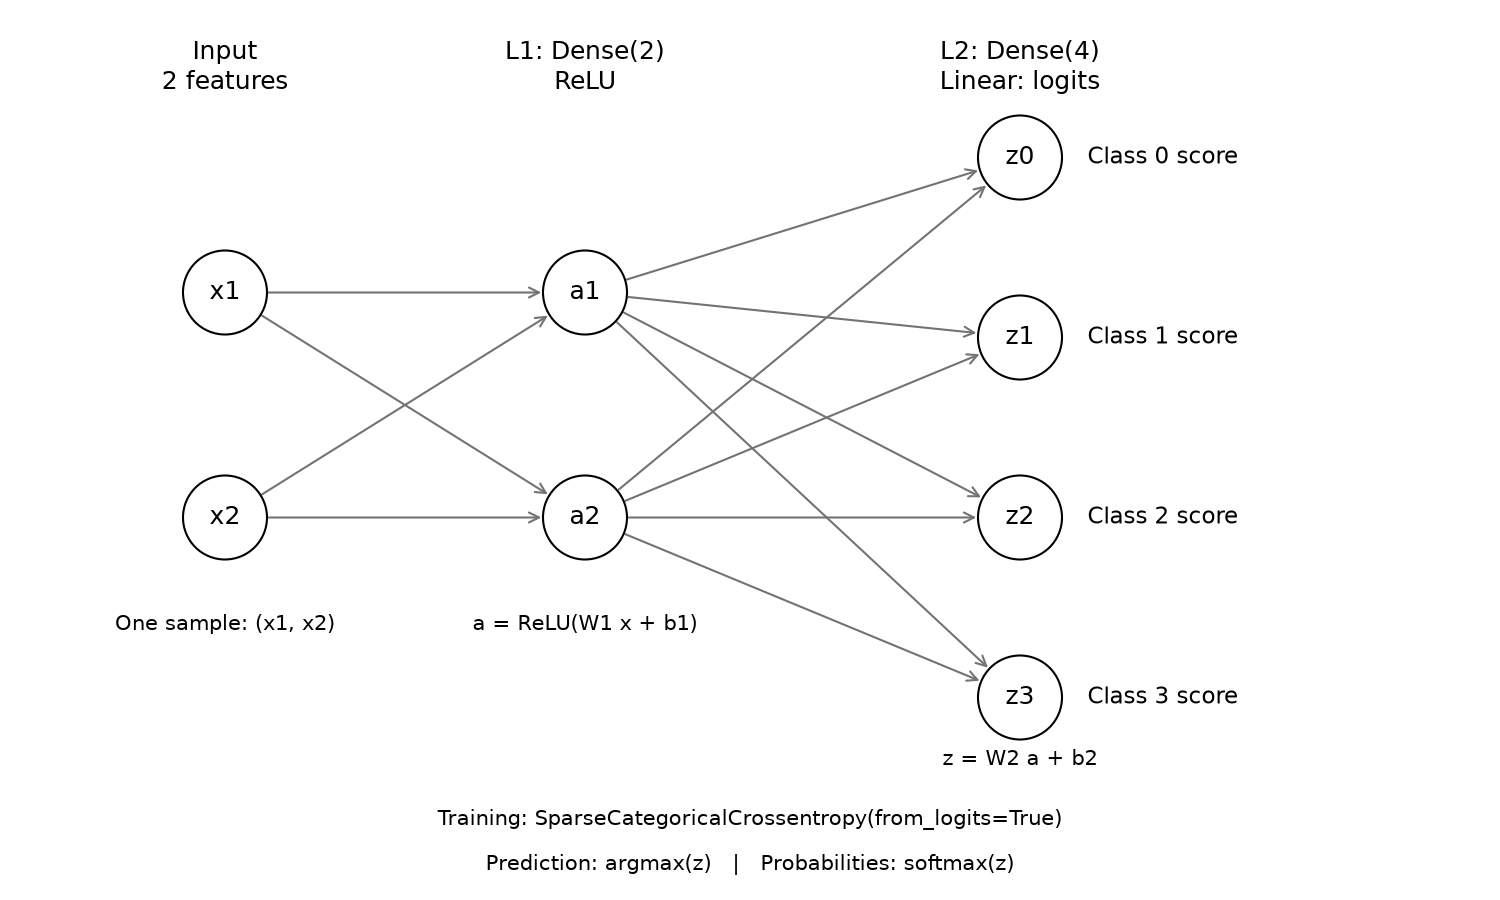

In [ ]:
# 网络结构图：2 个输入特征 → 2 个 ReLU 隐藏单元 → 4 个线性输出
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

nn_fig, nn_ax = plt.subplots(figsize=(10, 6))
nn_ax.set(xlim=(0, 940), ylim=(570, 0), aspect="equal")
nn_ax.axis("off")
nn_layers = [
    [(120, 180), (120, 330)],
    [(360, 180), (360, 330)],
    [(650, 90), (650, 210), (650, 330), (650, 450)],
]
for nn_left, nn_right in zip(nn_layers[:-1], nn_layers[1:]):
    for nn_start in nn_left:
        for nn_end in nn_right:
            nn_ax.add_patch(FancyArrowPatch(
                nn_start, nn_end, arrowstyle="->", mutation_scale=12,
                shrinkA=21, shrinkB=21, color="0.45", linewidth=1,
            ))
for nn_points, nn_labels in zip(nn_layers, [["x1", "x2"], ["a1", "a2"], ["z0", "z1", "z2", "z3"]]):
    for (nn_x, nn_y), nn_label in zip(nn_points, nn_labels):
        nn_ax.add_patch(Circle((nn_x, nn_y), 28, fill=False, edgecolor="black"))
        nn_ax.text(nn_x, nn_y, nn_label, ha="center", va="center", fontsize=12)
for nn_x, nn_title in [(120, "Input\n2 features"), (360, "L1: Dense(2)\nReLU"), (650, "L2: Dense(4)\nLinear: logits")]:
    nn_ax.text(nn_x, 30, nn_title, ha="center", va="center", fontsize=12)
for nn_i, (nn_x, nn_y) in enumerate(nn_layers[2]):
    nn_ax.text(nn_x + 45, nn_y, f"Class {nn_i} score", va="center", fontsize=11)
nn_ax.text(120, 405, "One sample: (x1, x2)", ha="center", fontsize=10)
nn_ax.text(360, 405, "a = ReLU(W1 x + b1)", ha="center", fontsize=10)
nn_ax.text(650, 495, "z = W2 a + b2", ha="center", fontsize=10)
nn_ax.text(470, 535, "Training: SparseCategoricalCrossentropy(from_logits=True)", ha="center", fontsize=10)
nn_ax.text(470, 565, "Prediction: argmax(z)   |   Probabilities: softmax(z)", ha="center", fontsize=10)
nn_fig.tight_layout()
plt.show()


In [4]:
tf.random.set_seed(1234) 
model = Sequential(
    [
        Dense(2, activation = 'relu', name = 'L1'),
        Dense(4, activation = 'linear', name = 'L2')
    ]
)

model.compile(
    # 为损失函数设置参数，表示输出激活是线性的，而不是 softmax
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01),
)

model.fit(
    X_train, y_train,
    epochs = 200,
)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 1.1960
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1130
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.0621
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.0318 
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.0159
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0049 
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9926 
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9781 
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9629 
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9453 
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9218 
Epoch 12/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.8952 
Epoch 13/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.8674 
Epoch 14/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.8344
Epoch 15/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.7967 
Epoch 16/200
4/4 ━━

184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step


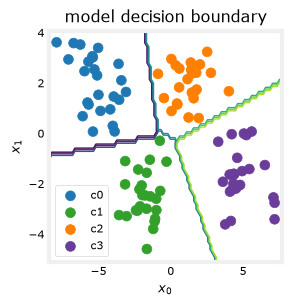

In [5]:
# 查看效果
plt_cat_mc(X_train, y_train, model, classes)

上面的决策边界展示了模型如何划分输入空间，这个非常简单的模型轻松完成了训练数据的分类，它如何做到的呢？

## 模型解释

我们将提取模型训练得到的参数，并据此绘制网络各单元的函数图像，以了解模型是如何工作的

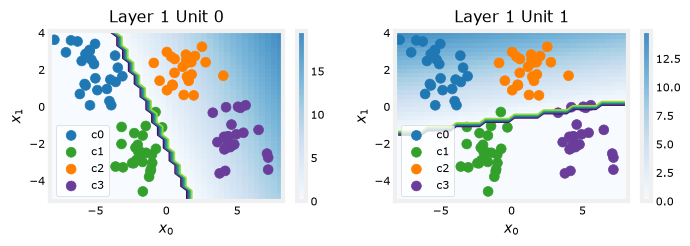

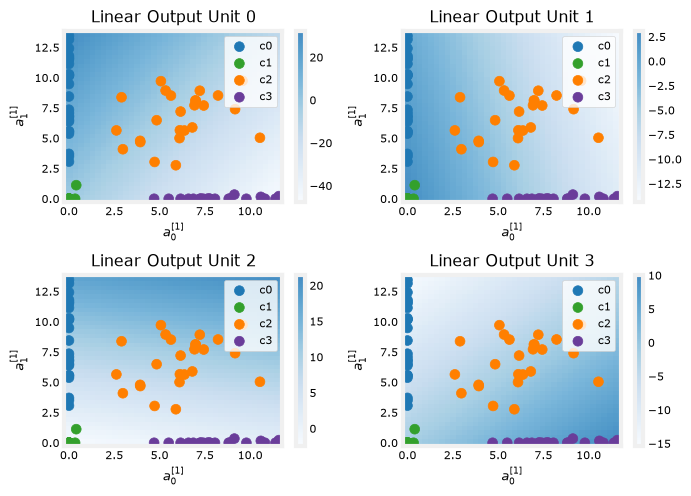

In [6]:
# 提取第一层训练得到的参数
l1 = model.get_layer('L1')
W1, b1 = l1.get_weights()

# 绘制第一层的函数
plt_layer_relu(X_train, y_train.reshape(-1, ), W1, b1, classes)

# 提取输出层训练得到的参数
l2 = model.get_layer("L2")
W2, b2 = l2.get_weights()
# 创建“新特征”，即训练样本经过 L1 变换后的结果
Xl2 = np.maximum(0, np.dot(X_train,W1) + b1)

plt_output_layer_linear(Xl2, y_train.reshape(-1,), W2, b2, classes,
                        x0_rng = (-0.25,np.amax(Xl2[:,0])), x1_rng = (-0.25,np.amax(Xl2[:,1])))